<a href="https://colab.research.google.com/github/shalaniupekshani/EN3160-Assignment-3-on-Neural-Networks/blob/main/A02_230659H.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 01 Single Dense Layer Network

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

In [3]:
# Data Loading
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
batch_size=50
trainset=torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
trainloader=torch.utils.data.DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=2)
testset=torchvision.datasets.CIFAR10(root="./data",train=False,download=True,transform=transform)
testloader=torch.utils.data.DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=2)
classes=('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

In [4]:
# Define Network Parameters
Din=3*32*32 #Input size (Flattened CIFAR-10 image size)
K=10 #Output size (Number of classes in CIFAR-10)
H=100 #middle layer with 100 nodes
std=1e-5

# Initialize weights and biases
#w=torch.randn(Din,K)*std #One layer: directly map input to output
#b=torch.zeros(K)
w1=torch.randn(Din,H)*std
b1=torch.zeros(H)

w2=torch.randn(H,K)*std
b2=torch.zeros(K)

# Hyperparameters
iterations=10
lr=2e-6 #learning rate
lr_decay=0.9 #learning rate decay
reg=0 #regularization
loss_history=[]

In [6]:
# Training Loop
for t in range(iterations):
    running_loss=0.0
    for i,data in enumerate(trainloader,0):
        #Get inputs and labels
        inputs,labels=data
        Ntr=inputs.shape[0] # Batch size
        x_train=inputs.view(Ntr,-1) #Flatten input to (Ntr,Din)
        y_train_onehot=nn.functional.one_hot(labels,K).float() # Convert labels to one hot

        #Forward pass
        #y_pred=x_train.mm(w)+b #output layer activation
        # Hidden Layer
        z1=x_train.mm(w1)+b1
        h=torch.sigmoid(z1)
        # Output layer
        y_pred=h.mm(w2)+b2

        #Loss calculation (mean square error with regularization)
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*torch.sum(w**2))
        #MSE Loss
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*(torch.sum(w1**2)+torch.sum(w2**2)))

        # Cross Entropy Loss
        loss=nn.functional.cross_entropy(y_pred,labels)+reg*(torch.sum(w1**2)+torch.sum(w2**2))
        loss_history.append(loss.item())
        running_loss+=loss.item()

        #Backpropagation
        #dy_pred=(2.0/Ntr)*(y_pred-y_train_onehot)
        #Backpropagation - logit
        probs=torch.softmax(y_pred,dim=1)
        dy_pred=(probs-y_train_onehot)/Ntr

        #dw=x_train.t().mm(dy_pred)+reg*w
        #db=dy_pred.sum(dim=0)

        # output layer
        dw2=h.t().mm(dy_pred)+2*reg*w2
        db2=dy_pred.sum(dim=0)
        #Hidden layer
        dh=dy_pred.mm(w2.t())
        dz1=dh*h*(1-h)
        dw1=x_train.t().mm(dz1)+2*reg*w1
        db1=dz1.sum(dim=0)

        #Parameter update
        #w-=lr*dw
        #b-=lr*db
        with torch.no_grad():
            w1-=lr*dw1
            b1-=lr*db1
            w2-=lr*dw2
            b2-=lr*db2

    # Print loss for every epoch
    if t%1==0:
        print(f"Epoch_{t+1}/{iterations},_Loss:_{running_loss/len(trainloader)}")
    #Learning rate decay
    lr*=lr_decay

Epoch_1/10,_Loss:_2.3025855631828307
Epoch_2/10,_Loss:_2.3025855288505555
Epoch_3/10,_Loss:_2.3025854601860045
Epoch_4/10,_Loss:_2.302585434436798
Epoch_5/10,_Loss:_2.302585406064987
Epoch_6/10,_Loss:_2.3025853695869447
Epoch_7/10,_Loss:_2.302585332393646
Epoch_8/10,_Loss:_2.3025853004455565
Epoch_9/10,_Loss:_2.3025852997303007
Epoch_10/10,_Loss:_2.302585270166397


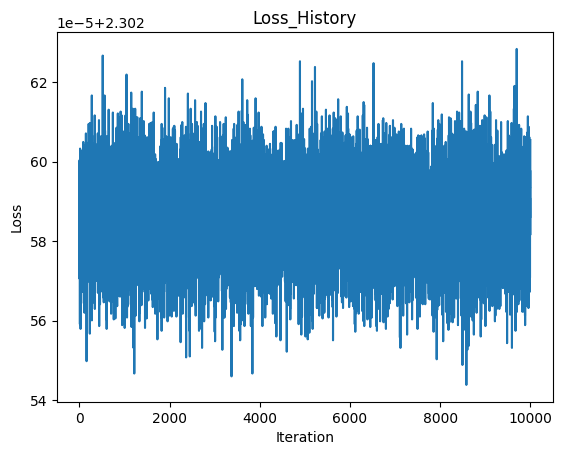

In [7]:
#Plotting Loss history
plt.plot(loss_history)
plt.title("Loss_History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [8]:
# calculate accuracy on Training Set
correct_train=0
total_train=0
with torch.no_grad():
    for data in trainloader:
        inputs,labels=data
        Ntr=inputs.shape[0]
        x_train=inputs.view(Ntr,-1)
        y_train_onehot=nn.functional.one_hot(labels,K).float()

        #Forward pass
        h=torch.sigmoid(x_train.mm(w1)+b1)
        y_train_pred=h.mm(w2)+b2
        predicted_train=torch.argmax(y_train_pred,dim=1)
        total_train+=labels.size(0)
        correct_train+=(predicted_train==labels).sum().item()

train_acc=100*correct_train/total_train
print(f"Training_accuracy: {train_acc:.2f}%")

Training_accuracy: 10.00%


In [9]:
# Calculate accuracy on Test Set
correct_test=0
total_test=0
with torch.no_grad():
    for data in testloader:
        inputs,labels=data
        Nte=inputs.shape[0]
        x_test=inputs.view(Nte,-1)
        y_test_onehot=nn.functional.one_hot(labels,K).float()

        # Forward Pass
        h=torch.sigmoid(x_test.mm(w1)+b1)
        y_test_pred=h.mm(w2)+b2
        predicted_test=torch.argmax(y_test_pred,dim=1)
        total_test+=labels.size(0)
        correct_test+=(predicted_test==labels).sum().item()

test_acc=100*correct_test/total_test
print(f"Test_accuracy: {test_acc:.2f}%")

Test_accuracy: 10.00%


A two-layer neural network was implemented by adding a hidden layer containing 100 neurons with sigmoid activation to the original single-layer network. Cross-entropy loss was used for classification, and the gradients were calculated manually using backpropagation. The network was trained on the CIFAR-10 dataset for 10 epochs.

The resulting training accuracy was 10%, and the test accuracy was 10%. These results indicate the model's performance on the training and unseen test datasets. The difference between the two accuracies can provide an indication of how well the network generalizes to unseen images.

Question 02 LeNet-5 network for MNIST using Pytorch

In [10]:
# Transform images into tensor and normalize
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.1307,),(0.3081,))])
# Load MNIST dataset
train_dataset=torchvision.datasets.MNIST(root="./data",train=True,download=True,transform=transform)
test_dataset=torchvision.datasets.MNIST(root="./data",train=False,download=True,transform=transform)

# create data loaders
train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False)

#Select CPU or GPU
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:",device)

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.69MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.95MB/s]

Using device: cpu


In [15]:
# Define the LeNet-5 model
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5,self).__init__()
        self.features=nn.Sequential(
            #Convolutional layer 1
            nn.Conv2d(1,6,kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2,stride=2),

            #Convolution layer 2
            nn.Conv2d(6,16,kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2,stride=2)
        )
        self.classifier=nn.Sequential(
            nn.Linear(16*4*4,120),
            nn.Tanh(),
            nn.Linear(120,84),
            nn.Tanh(),
            nn.Linear(84,10)
        )

    def forward(self,x):
      x=self.features(x)
      x=torch.flatten(x,1)
      x=self.classifier(x)
      return x
model=LeNet5().to(device)
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(model.parameters(),lr=0.01,momentum=0.9)
print(model)

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=120, bias=True)
    (1): Tanh()
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): Tanh()
    (4): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [19]:
def evaluate(model,loaders):
  model.eval()
  correct=0
  total=0
  total_loss=0.0

  with torch.no_grad():
    for images,labels in loaders:
      images,labels=images.to(device),labels.to(device)
      outputs=model(images)
      loss=criterion(outputs,labels)
      total_loss+=loss.item()*labels.size(0)
      _,predicted=torch.max(outputs.data,1)
      total+=labels.size(0)
      correct+=(predicted==labels).sum().item()

  accuracy=100*correct/total
  avg_loss=total_loss/total
  return avg_loss,accuracy

epochs=10
for epoch in range(epochs):
  model.train()
  running_loss=0.0
  correct=0
  total=0
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    #forward pass
    outputs=model(images)
    loss=criterion(outputs,labels)

    #backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    running_loss+=loss.item()*labels.size(0)
    _,predicted=torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  train_loss=running_loss/total
  train_accuracy=100*correct/total
  test_loss,test_accuracy=evaluate(model,test_loader)

  print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

Epoch 1/10, Train Loss: 0.4150, Train Accuracy: 87.79%, Test Loss: 0.1166, Test Accuracy: 96.38%
Epoch 2/10, Train Loss: 0.0933, Train Accuracy: 97.19%, Test Loss: 0.0611, Test Accuracy: 97.98%
Epoch 3/10, Train Loss: 0.0624, Train Accuracy: 98.09%, Test Loss: 0.0454, Test Accuracy: 98.54%
Epoch 4/10, Train Loss: 0.0508, Train Accuracy: 98.42%, Test Loss: 0.0420, Test Accuracy: 98.65%
Epoch 5/10, Train Loss: 0.0429, Train Accuracy: 98.73%, Test Loss: 0.0369, Test Accuracy: 98.69%
Epoch 6/10, Train Loss: 0.0375, Train Accuracy: 98.87%, Test Loss: 0.0358, Test Accuracy: 98.73%
Epoch 7/10, Train Loss: 0.0330, Train Accuracy: 98.98%, Test Loss: 0.0323, Test Accuracy: 98.81%
Epoch 8/10, Train Loss: 0.0289, Train Accuracy: 99.10%, Test Loss: 0.0355, Test Accuracy: 98.88%
Epoch 9/10, Train Loss: 0.0266, Train Accuracy: 99.15%, Test Loss: 0.0287, Test Accuracy: 99.04%
Epoch 10/10, Train Loss: 0.0239, Train Accuracy: 99.26%, Test Loss: 0.0305, Test Accuracy: 98.94%


In [20]:
train_loss, train_accuracy = evaluate(model, train_loader)
test_loss, test_accuracy = evaluate(model, test_loader)

print("\nFinal Results After 10 Epochs")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")


Final Results After 10 Epochs
Train Loss: 0.0201, Train Accuracy: 99.39%
Test Loss: 0.0305, Test Accuracy: 98.94%


Part b - mplementing a Modern Small CNN

In [21]:
class ModernSmallCNN(nn.Module):
    def __init__(self):
        super(ModernSmallCNN, self).__init__()
        self.features = nn.Sequential(
            #Convolution layer 1
            nn.Conv2d(1,32,kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #Convolution layer 2
            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #convolution layer 3
            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Dropout2d(0.25)
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*7*7,128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128,10)
        )

    def forward(self,x):
        x=self.features(x)
        x=self.classifier(x)
        return x
model_cnn=ModernSmallCNN().to(device)
criterion_cnn=nn.CrossEntropyLoss()
optimizer_cnn=optim.SGD(model_cnn.parameters(),lr=0.01,momentum=0.9)
print(model_cnn)


ModernSmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout2d(p=0.25, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Line

In [22]:
epochs=10
for epoch in range(epochs):
  model_cnn.train()
  running_loss=0.0
  correct=0
  total=0
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    #forward pass
    outputs=model_cnn(images)
    loss=criterion_cnn(outputs,labels)

    #backpropagation
    optimizer_cnn.zero_grad()
    loss.backward()
    optimizer_cnn.step()
    running_loss+=loss.item()*labels.size(0)
    _,predicted=torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  train_loss=running_loss/total
  train_accuracy=100*correct/total
  test_loss,test_accuracy=evaluate(model_cnn,test_loader)

  print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

Epoch 1/10, Train Loss: 0.1747, Train Accuracy: 94.64%, Test Loss: 0.0453, Test Accuracy: 98.58%
Epoch 2/10, Train Loss: 0.0738, Train Accuracy: 97.79%, Test Loss: 0.0274, Test Accuracy: 99.02%
Epoch 3/10, Train Loss: 0.0555, Train Accuracy: 98.36%, Test Loss: 0.0278, Test Accuracy: 99.11%
Epoch 4/10, Train Loss: 0.0451, Train Accuracy: 98.64%, Test Loss: 0.0291, Test Accuracy: 99.11%
Epoch 5/10, Train Loss: 0.0417, Train Accuracy: 98.77%, Test Loss: 0.0233, Test Accuracy: 99.20%
Epoch 6/10, Train Loss: 0.0345, Train Accuracy: 98.96%, Test Loss: 0.0179, Test Accuracy: 99.36%
Epoch 7/10, Train Loss: 0.0301, Train Accuracy: 99.09%, Test Loss: 0.0195, Test Accuracy: 99.29%
Epoch 8/10, Train Loss: 0.0276, Train Accuracy: 99.13%, Test Loss: 0.0197, Test Accuracy: 99.34%
Epoch 9/10, Train Loss: 0.0240, Train Accuracy: 99.25%, Test Loss: 0.0211, Test Accuracy: 99.29%
Epoch 10/10, Train Loss: 0.0221, Train Accuracy: 99.31%, Test Loss: 0.0191, Test Accuracy: 99.50%


Part c - Comparison

In [ ]:
lenet_his={
    'train_loss':[],
    'train_acc':[],
    'test_loss':[],
    'test_acc':[]
}
cnn_his={
    'train_loss':[],
    'train_acc':[],
    'test_loss':[],
    'test_acc':[]
}

In [23]:
def train_and_log(model,optimizer,criterion,history,epochs=10):
  for epoch in range(epochs):
    model.train()
    running_loss=0.0
    correct=0
    total=0

    for images,labels in train_loader:
      images,labels=images.to(device),labels.to(device)
      outputs=model(images)
      loss=criterion(outputs,labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      running_loss+=loss.item()*labels.size(0)
      _,predicted=torch.max(outputs,1)
      total+=labels.size(0)
      correct+=(predicted==labels).sum().item()

    train_loss=running_loss/total
    train_accuracy=100*correct/total
    test_loss,test_accuracy=evaluate(model,test_loader)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_accuracy)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_accuracy)
    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")